# Telco Customer Churn
**Residency Day 2 · Project Deliverable 2**  
**Regression Modeling and Performance Evaluation**  
MSCS-634-M50 · Advanced Big Data and Data Mining  
Group project · Federico Poi and Umama Azhar

In Deliverable 1, we saw that monthly bills varied by internet service and that customers with multiple phone lines could have higher bills even without internet. This time we predict `MonthlyCharges`, the customer's monthly bill in dollars. We compare multiple linear regression and Ridge, then check whether two engineered features improve predictions and whether the service details alone are enough.

We use the same [IBM Telco Customer Churn dataset](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv) as before. It contains one row per customer, with 7,043 rows and 21 columns.

## 1. Load the data and choose the target

We exclude the customer ID, the churn label, and `TotalCharges`. Cumulative charges record past billing and could give the model indirect information about the monthly bill. None of the predictors we use needs that column, so the 11 customers with blank totals can stay in the analysis.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Read the same public IBM CSV used in Deliverable 1.
source_url = (
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)
df = pd.read_csv(source_url)

# Set aside the outcome and remove columns excluded from the model.
y = df["MonthlyCharges"]
X_baseline = df.drop(columns=[
    "MonthlyCharges", "customerID", "TotalCharges", "Churn"
])

# Check that each row has a distinct customer and complete modeling inputs.
assert df["customerID"].is_unique
assert not y.isna().any()
assert not X_baseline.isna().any().any()
print(f"{df.shape[0]:,} customers, {df.shape[1]} columns in the source data")
print(f"{X_baseline.shape[1]} original predictors")

Matplotlib is building the font cache; this may take a moment.


7,043 customers, 21 columns in the source data
17 original predictors


## 2. Engineer features and define the comparison

- **InternetAddonCount** counts how many of the six internet add-ons each customer uses. The original add-on columns already contain this information. We wanted to see whether summarizing it helped Ridge.
- **FiberAddonCount** uses the add-on count for fiber optic customers and zero for everyone else. This lets either linear model estimate a different bill change for each additional add-on for fiber customers.

We also test a smaller set of nine service columns. Those are internet service, phone service, multiple lines, online security, online backup, device protection, tech support, streaming TV, and streaming movies.

In [2]:
# Only "Yes" counts as a subscription. "No" and "No internet service" add zero.
addon_columns = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
addon_count = X_baseline[addon_columns].eq("Yes").sum(axis=1)
assert addon_count.between(0, len(addon_columns)).all()

# Keep the count-only version to measure what each added feature contributes.
X_count_only = X_baseline.assign(InternetAddonCount=addon_count)

# The interaction is zero for customers without fiber optic service.
is_fiber = X_baseline["InternetService"].eq("Fiber optic")
X_engineered = X_count_only.assign(FiberAddonCount=addon_count * is_fiber)

# Keep only columns that describe the services on the customer's account.
service_columns = ["InternetService", "PhoneService", "MultipleLines"] + addon_columns
X_services = X_baseline[service_columns]

print("Original features:", X_baseline.shape[1])
print("Engineered features added:", X_engineered.shape[1] - X_baseline.shape[1])
print("Total features:", X_engineered.shape[1])
print("Services-only features:", X_services.shape[1])
display(X_engineered[["InternetService", "InternetAddonCount", "FiberAddonCount"]].head())

Original features: 17
Engineered features added: 2
Total features: 19
Services-only features: 9


,InternetService,InternetAddonCount,FiberAddonCount
0,DSL,1,0
1,DSL,2,0
2,DSL,2,0
3,DSL,3,0
4,Fiber optic,0,0


## 3. Split the data and build the models

We set aside 20% of customers for testing, then compare models with five-fold cross-validation on the remaining 80%. Every configuration uses the same customers in each fold. We fit the encoder and scaler inside each model pipeline so they learn only from the training rows of that fold.

Both models use multiple predictors. Ridge adds a penalty that shrinks coefficients. We use a fixed Ridge penalty of `alpha=1.0` for this comparison.

In [3]:
# Split the row indices once so all feature sets and targets stay aligned.
train_index, test_index = train_test_split(df.index, test_size=0.20, random_state=42)
y_train = y.loc[train_index]
y_test = y.loc[test_index]
feature_sets = {
    "Original (17)": X_baseline,
    "Add-on count (18)": X_count_only,
    "Both new features (19)": X_engineered,
    "Services only (9)": X_services,
}

# Freeze fold positions so both regressors see the same validation customers.
folds = KFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(folds.split(y_train))
print(f"{len(y_train):,} training customers and {len(y_test):,} test customers")


def build_model(regressor):
    # Scale numeric inputs for Ridge and turn service categories into indicators.
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), make_column_selector(dtype_include="number")),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         make_column_selector(dtype_exclude="number")),
    ])
    return make_pipeline(preprocessing, regressor)


# Each call creates a fresh regressor for fitting.
model_builders = {
    "Multiple Linear Regression": LinearRegression,
    "Ridge": lambda: Ridge(alpha=1.0),
}

5,634 training customers and 1,409 test customers


## 4. Compare cross-validation scores

We use mean RMSE to rank the configurations because it expresses error in dollars and gives larger misses more weight. MSE reports the squared error in dollars squared. R² measures how much squared error the model reduces relative to predicting the mean of the evaluation targets. We also report the standard deviation of RMSE across the five folds to show how much error varied across customer groups.

In [4]:
# Use a common set of evaluation metrics for each fold.
scoring = {
    "r2": "r2",
    "mse": "neg_mean_squared_error",
    "rmse": "neg_root_mean_squared_error",
}
cv_rows = []

for model_name, make_regressor in model_builders.items():
    for feature_name, features in feature_sets.items():
        # Cross-validation fits a fresh pipeline on four folds and scores the fifth.
        scores = cross_validate(
            build_model(make_regressor()), features.loc[train_index], y_train,
            cv=cv_splits, scoring=scoring, error_score="raise",
        )
        # Convert the negative error scores back into positive errors.
        fold_rmse = -scores["test_rmse"]
        cv_rows.append({
            "Model": model_name,
            "Features": feature_name,
            "Mean CV R²": scores["test_r2"].mean(),
            "Mean CV MSE": -scores["test_mse"].mean(),
            "Mean CV RMSE": fold_rmse.mean(),
            "CV RMSE Std": fold_rmse.std(ddof=1),
        })

# Rank on unrounded scores. Round only the displayed values.
cv_results = pd.DataFrame(cv_rows).sort_values("Mean CV RMSE").reset_index(drop=True)
display(cv_results.round(4))

,Model,Features,Mean CV R²,Mean CV MSE,Mean CV RMSE,CV RMSE Std
0,Multiple Linear Regression,Services only (9),0.9988,1.0420,1.0203,0.0369
1,Ridge,Services only (9),0.9988,1.0421,1.0203,0.0370
2,Multiple Linear Regression,Original (17),0.9988,1.0454,1.0219,0.0376
3,Multiple Linear Regression,Add-on count (18),0.9988,1.0454,1.0219,0.0376
4,Ridge,Add-on count (18),0.9988,1.0454,1.0219,0.0379
5,Ridge,Original (17),0.9988,1.0455,1.0219,0.0378
6,Multiple Linear Regression,Both new features (19),0.9988,1.0461,1.0222,0.0373
7,Ridge,Both new features (19),0.9988,1.0463,1.0223,0.0380


## 5. Test the best configuration for each model

We select each model's feature set using cross-validation scores. Then we refit each selection on all 5,634 training customers and evaluate both models on the same 1,409 test customers.

In [5]:
# Keep the best feature set for each model based on validation RMSE.
best_per_model = cv_results.drop_duplicates(subset="Model")
test_rows = []
test_predictions = {}

for row in best_per_model.to_dict("records"):
    model_name = row["Model"]
    feature_name = row["Features"]
    features = feature_sets[feature_name]

    # Refit using all training customers and predict the held-out test set.
    model = build_model(model_builders[model_name]())
    model.fit(features.loc[train_index], y_train)
    predictions = model.predict(features.loc[test_index])
    test_predictions[model_name] = predictions

    mse = mean_squared_error(y_test, predictions)
    test_rows.append({
        "Model": model_name,
        "Features": feature_name,
        "Test R²": r2_score(y_test, predictions),
        "Test MSE": mse,
        "Test RMSE": mse ** 0.5,
    })

test_results = pd.DataFrame(test_rows)
display(test_results.round(4))

winner = cv_results.iloc[0]
print(
    f"Best by cross-validation: {winner['Model']} with {winner['Features']} "
    f"(mean RMSE: {winner['Mean CV RMSE']:.4f} dollars)"
)

,Model,Features,Test R²,Test MSE,Test RMSE
0,Multiple Linear Regression,Services only (9),0.9988,1.1034,1.0504
1,Ridge,Services only (9),0.9988,1.1038,1.0506


Best by cross-validation: Multiple Linear Regression with Services only (9) (mean RMSE: 1.0203 dollars)


## 6. Visualize performance

The left chart compares validation RMSE across all four feature sets. Its error bars show one standard deviation across folds. The right chart compares typical prediction error on the held-out test set for the two selected models.

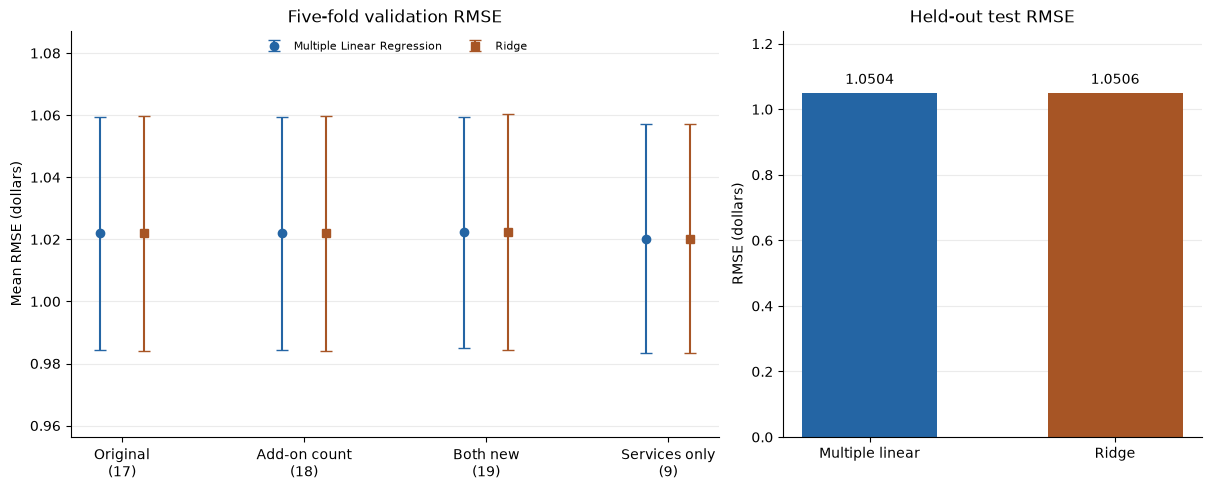

In [6]:
# Plot the two models side by side for each feature set and on the test set.
fig, (cv_ax, test_ax) = plt.subplots(
    1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.55, 1]},
    layout="constrained",
)
colors = {"Multiple Linear Regression": "#2465a4", "Ridge": "#a75525"}
markers = {"Multiple Linear Regression": "o", "Ridge": "s"}
positions = list(range(len(feature_sets)))

for model_name, offset in zip(model_builders, [-0.12, 0.12]):
    comparison = (
        cv_results[cv_results["Model"].eq(model_name)]
        .set_index("Features").loc[list(feature_sets)]
    )
    cv_ax.errorbar(
        [position + offset for position in positions], comparison["Mean CV RMSE"],
        yerr=comparison["CV RMSE Std"], fmt=markers[model_name], capsize=4,
        color=colors[model_name], label=model_name,
    )

cv_ax.set_xticks(positions, ["Original\n(17)", "Add-on count\n(18)",
                            "Both new\n(19)", "Services only\n(9)"])
cv_ax.set(title="Five-fold validation RMSE", ylabel="Mean RMSE (dollars)")
cv_ax.legend(loc="upper center", frameon=False, ncols=2, fontsize=8)
cv_ax.margins(y=0.35)

bars = test_ax.bar(
    test_results["Model"].replace({"Multiple Linear Regression": "Multiple linear"}),
    test_results["Test RMSE"],
    color=[colors[model_name] for model_name in test_results["Model"]], width=0.55,
)
test_ax.set(title="Held-out test RMSE", ylabel="RMSE (dollars)",
            ylim=(0, test_results["Test RMSE"].max() * 1.18))
test_ax.bar_label(bars, fmt="%.4f", padding=4)

for axis in (cv_ax, test_ax):
    axis.set_axisbelow(True)
    axis.grid(axis="y", alpha=0.25)
    axis.spines[["top", "right"]].set_visible(False)

plt.show()

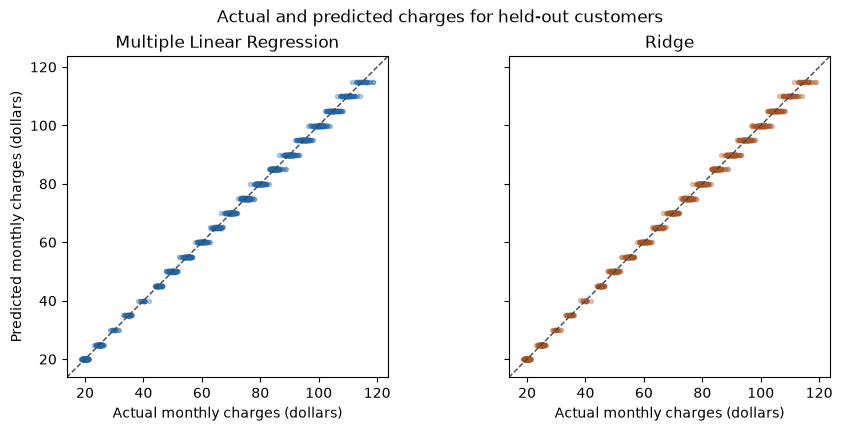

In [7]:
# Compare actual and predicted monthly charges for both selected models.
# Points near the diagonal represent accurate predictions.
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True,
                         layout="constrained")
limits = [y_test.min() - 5, y_test.max() + 5]
for axis, (model_name, predictions) in zip(axes, test_predictions.items()):
    axis.scatter(y_test, predictions, s=9, alpha=0.3, color=colors[model_name])
    axis.plot(limits, limits, linestyle="--", color="#3e4650", linewidth=1)
    axis.set(title=model_name, xlabel="Actual monthly charges (dollars)",
             xlim=limits, ylim=limits, aspect="equal")

axes[0].set_ylabel("Predicted monthly charges (dollars)")
fig.suptitle("Actual and predicted charges for held-out customers")
plt.show()

## 7. What we learned

Multiple Linear Regression with nine service features had the lowest mean validation RMSE at 1.0203 dollars. Ridge with the same inputs rounded to the same score. On the held-out test set, RMSE was 1.0504 dollars for Multiple Linear Regression and 1.0506 dollars for Ridge. Both models had a test R² of 0.9988. The errors were close enough that we would choose Multiple Linear Regression for its simpler setup.

The add-on count made little difference. Adding the fiber interaction increased validation RMSE slightly for both models. The nine original service columns performed about as well as the full set of 17 predictors, so we can estimate monthly charges from the services on the customer’s account with eight fewer inputs. That makes sense for this task because the target is the bill for a known service bundle. The results describe this sample and do not establish how well the model would work under a different pricing structure.